### 检索器：调优 - 上下文压缩
---
* LLMChainExtractor
* LLMChainFilter
* 多个压缩器组合管道

In [7]:
from langchain_deepseek import ChatDeepSeek
from dotenv import load_dotenv
import os

load_dotenv()

model = ChatDeepSeek(
    model="deepseek-ai/DeepSeek-V4.1-Flash",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

def pretty_print_docs(docs):
    print(
        f"\n{'-' * 100}\n".join(
            [f"Document {i+1}:\n\n" + d.page_content for i, d in enumerate(docs)]
        )
    )

### 上下文压缩
---
未优化前使用向量库自带能力

In [8]:
from langchain_community.document_loaders import TextLoader
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAIEmbeddings
from langchain_text_splitters import CharacterTextSplitter

embeddings_model = OpenAIEmbeddings(
    model="Qwen/Qwen3-Embedding-8B",       # 指定使用的 Embedding 模型名称
    openai_api_key=os.getenv("api_key"),   # 从环境变量读取 API 密钥
    openai_api_base=os.getenv("base_url")  # 从环境变量读取 API 请求地址（兼容 OpenAI 格式的自定义端点）
)

documents = TextLoader("test.txt", encoding="utf-8").load()
text_splitter = CharacterTextSplitter(chunk_size=1000, chunk_overlap=0)
texts = text_splitter.split_documents(documents=documents)
retriever = FAISS.from_documents(texts, embeddings_model).as_retriever()

docs = retriever.invoke("如何进行模型部署")
pretty_print_docs(docs)

Document 1:

response = llm.invoke("如何进行模型部署？")
print(response.content)
方案二：高性能、生产环境首选 👉 vLLM
如果你有 Linux 服务器 和 NVIDIA GPU（如 RTX 3090/4090, A10, A100），并且需要高吞吐量、支持多用户并发，vLLM 是目前业界部署开源大模型的标准答案。它的推理速度极快，且原生支持 DeepSeek 的 MoE 架构和 PagedAttention。
1. 环境准备
确保已安装 NVIDIA 驱动、CUDA (>=12.1) 和 Python (>=3.9)。
2. 安装 vLLM
bash
pip install vllm
3. 启动模型服务
使用 vllm serve 命令启动一个兼容 OpenAI API 格式的本地服务。这里以 DeepSeek-R1-Distill-Qwen-8B 为例：
bash
# 启动服务，监听 8000 端口
vllm serve deepseek-ai/DeepSeek-R1-Distill-Qwen-8B \
    --dtype auto \
    --api-key token-abc123 \
    --max-model-len 8192
(提示：首次运行会自动从 HuggingFace 下载模型权重，国内网络建议配置 HF_ENDPOINT=https://hf-mirror.com)
4. 在 LangChain 中调用
vLLM 启动后，完全兼容 OpenAI 的 API 协议，你可以直接使用 ChatOpenAI 指向本地端口：
python
import os
from langchain_openai import ChatOpenAI

# 指向本地 vLLM 服务
llm = ChatOpenAI(
    model="deepseek-ai/DeepSeek-R1-Distill-Qwen-8B",
    openai_api_key="token-abc123",  # 必须与启动时设置的 api-key 一致
    openai_api_base="http://localhost:8000/v1",
    temperature=0
)
-----------

In [9]:
import os
from dotenv import load_dotenv
from langchain_core.documents import Document  # ✅ 从 core 导入 Document
from langchain_openai import OpenAIEmbeddings
from langchain_text_splitters import CharacterTextSplitter
from langchain_community.vectorstores import FAISS # FAISS 目前仍在此包中

load_dotenv()

# 1. 初始化嵌入模型
embeddings_model = OpenAIEmbeddings(
    model="Qwen/Qwen3-Embedding-8B",
    openai_api_key=os.getenv("api_key"),
    openai_api_base=os.getenv("base_url")
)

# ==========================================
# ✅ 2. 替换 TextLoader：使用 Python 原生读取
# ==========================================
file_path = "test.txt"
with open(file_path, "r", encoding="utf-8") as f:
    text_content = f.read()

# 将读取的字符串手动封装为 LangChain 的 Document 对象列表
documents = [Document(page_content=text_content, metadata={"source": file_path})]

# 3. 文本切分
text_splitter = CharacterTextSplitter(chunk_size=1000, chunk_overlap=50)
texts = text_splitter.split_documents(documents=documents)

# 4. 构建向量数据库并创建检索器
vectorstore = FAISS.from_documents(texts, embeddings_model)
retriever = vectorstore.as_retriever(search_kwargs={"k": 3})

# 5. 执行检索
query = "如何进行模型部署"
docs = retriever.invoke(query)

# 6. 打印结果
print(f"\n🔍 针对问题: '{query}'，检索到 {len(docs)} 个相关文档片段:\n")
for i, doc in enumerate(docs):
    print(f"--- 片段 {i+1} ---")
    print(f"内容: {doc.page_content[:100]}...") # 截取前100个字符方便预览
    print(f"来源: {doc.metadata.get('source', '未知')}\n")


🔍 针对问题: '如何进行模型部署'，检索到 3 个相关文档片段:

--- 片段 1 ---
内容: response = llm.invoke("如何进行模型部署？")
print(response.content)
方案二：高性能、生产环境首选 👉 vLLM
如果你有 Linux 服务器 和 NV...
来源: test.txt

--- 片段 2 ---
内容: 部署 DeepSeek 模型主要取决于你的硬件条件（是否有 GPU、显存大小）以及使用场景（个人本地测试 vs 企业级高并发生产环境）。
以下是目前业界最主流的 3 种 DeepSeek 模型部署方案...
来源: test.txt

--- 片段 3 ---
内容: DeepSeek（深度求索）是一家中国的人工智能研究公司（杭州深度求索人工智能基础技术研究有限公司），在人工智能和大语言模型（LLM）领域非常知名。
它主要以开发高性能、高性价比的开源和闭源大模型而受...
来源: test.txt



* 使用 LLMChainExtractor  


   基础检索器ContextualCompressionRetiever以及LLMChainExtractor，它将迭代最初返回的文档，并从每个文档中仅提取与查询相关的内容

In [10]:
from langchain_classic.retrievers import ContextualCompressionRetriever
from langchain_classic.retrievers.document_compressors import LLMChainExtractor

compressor = LLMChainExtractor.from_llm(model)
compression_retriever = ContextualCompressionRetriever(
    base_compressor=compressor, base_retriever=retriever
)

compressed_docs = compression_retriever.invoke(
    "如何进行部署"
)

pretty_print_docs(compressed_docs)

Document 1:

部署 DeepSeek 模型主要取决于你的硬件条件（是否有 GPU、显存大小）以及使用场景（个人本地测试 vs 企业级高并发生产环境）。
以下是目前业界最主流的 3 种 DeepSeek 模型部署方案，按从易到难排序：
方案一：最简单、最适合个人本地测试 👉 Ollama
如果你使用的是个人电脑（Mac M系列芯片，或带有 NVIDIA 显卡的 Windows/Linux 电脑），Ollama 是绝对的首选。它一键安装，自动处理底层的量化和显存优化。
1. 安装 Ollama
前往官网 ollama.com 下载并安装对应系统的客户端。
2. 下载并运行模型
打开终端（或 PowerShell），运行以下命令（以 DeepSeek-R1 的 8B 蒸馏版为例，适合 16GB 左右显存的设备）：
bash
# 拉取并运行模型 (首次运行会自动下载约 5GB 的文件)
ollama run deepseek-r1:8b
(注：如果你的显存较大，可以尝试 deepseek-r1:14b 或 deepseek-r1:32b)
3. 在 LangChain 中调用
部署好后，Ollama 会在本地 http://localhost:11434 启动一个兼容 OpenAI 格式的 API 服务。你可以这样在代码中调用：
python
from langchain_community.chat_models import ChatOllama

# 直接连接本地 Ollama 服务
llm = ChatOllama(
    model="deepseek-r1:8b",
    base_url="http://localhost:11434",
    temperature=0
)
----------------------------------------------------------------------------------------------------
Document 2:

方案二：高性能、生产环境首选 👉 vLLM
如果你有 Linux 服务器 和 NVIDIA GPU（如 RTX 3090/4090, A10, A100），并且需要高吞吐量、支持多用户并发，vLLM 是目前业界部署开源大模型的标准答案。它的推理速

LLMChainFiter：使用LLM链来决定过滤掉哪些最初检索到的文档以及返回哪些文档，而无需操作文档内容

In [11]:
from langchain_classic.retrievers.document_compressors import LLMChainFilter

_filter = LLMChainFilter.from_llm(model)

compression_retriever = ContextualCompressionRetriever(
    base_compressor=_filter, base_retriever=retriever
)

compressed_docs = compression_retriever.invoke(
    "如何进行部署"
)

pretty_print_docs(compressed_docs)

Document 1:

部署 DeepSeek 模型主要取决于你的硬件条件（是否有 GPU、显存大小）以及使用场景（个人本地测试 vs 企业级高并发生产环境）。
以下是目前业界最主流的 3 种 DeepSeek 模型部署方案，按从易到难排序：
方案一：最简单、最适合个人本地测试 👉 Ollama
如果你使用的是个人电脑（Mac M系列芯片，或带有 NVIDIA 显卡的 Windows/Linux 电脑），Ollama 是绝对的首选。它一键安装，自动处理底层的量化和显存优化。
1. 安装 Ollama
前往官网 ollama.com 下载并安装对应系统的客户端。
2. 下载并运行模型
打开终端（或 PowerShell），运行以下命令（以 DeepSeek-R1 的 8B 蒸馏版为例，适合 16GB 左右显存的设备）：
bash
# 拉取并运行模型 (首次运行会自动下载约 5GB 的文件)
ollama run deepseek-r1:8b
(注：如果你的显存较大，可以尝试 deepseek-r1:14b 或 deepseek-r1:32b)
3. 在 LangChain 中调用
部署好后，Ollama 会在本地 http://localhost:11434 启动一个兼容 OpenAI 格式的 API 服务。你可以这样在代码中调用：
python
from langchain_community.chat_models import ChatOllama

# 直接连接本地 Ollama 服务
llm = ChatOllama(
    model="deepseek-r1:8b",
    base_url="http://localhost:11434",
    temperature=0
)
----------------------------------------------------------------------------------------------------
Document 2:

response = llm.invoke("如何进行模型部署？")
print(response.content)
方案二：高性能、生产环境首选 👉 vLLM
如果你有 Linux 服务器 和 NVIDIA GPU（如 RTX 3090/409

### 多个压缩器组合管道
---
* 使用DocumentCompressorPipeline轻松地按顺序组合多个压缩器
* 将文档拆解成更小的碎片
* 删除冗余文档
* 串联多个压缩器

In [ ]:
from langchain_classic.retrievers.document_compressors import DocumentCompressorPipeline
from langchain_community.document_transformers import EmbeddingsRedundantFilter
from langchain_text_splitters import CharacterTextSplitter
from langchain_classic.retrievers.document_compressors import EmbeddingsFilter

splitter = CharacterTextSplitter(chunk_size=400, chunk_overlap=0, separator=". ")
redundant_filter = EmbeddingsRedundantFilter(embeddings=embeddings_model)
relevant_filter = EmbeddingsFilter(embeddings=embeddings_model, similarity_threshold=0.76)
pipeline_compressor = DocumentCompressorPipeline(
    transformers=[splitter, redundant_filter, relevant_filter]
)

compression_retriever = ContextualCompressionRetriever(
    base_compressor=pipeline_compressor, base_retriever=retriever
)

compressed_docs = compression_retriever.invoke(
    "如何进行部署"
)

pretty_print_docs(compressed_docs)

In [17]:
import os
from dotenv import load_dotenv

# 1. 补全缺失的导入
from langchain_classic.retrievers import ContextualCompressionRetriever  # ✅ 修复：补充此导入
from langchain_classic.retrievers.document_compressors import DocumentCompressorPipeline # ✅ 推荐使用标准路径
from langchain_community.document_transformers import EmbeddingsRedundantFilter
from langchain_classic.retrievers.document_compressors import EmbeddingsFilter
from langchain_text_splitters import CharacterTextSplitter

load_dotenv()

# 假设你之前已经定义了 embeddings_model 和 retriever，这里为了代码完整，做个占位说明：
# embeddings_model = OpenAIEmbeddings(...)
# retriever = FAISS.from_documents(...).as_retriever()

# 2. 定义压缩管道 (Pipeline)
# 逻辑：先切分大块文档 -> 剔除相互之间高度重复的冗余文档 -> 剔除与问题相关性低于阈值的文档
splitter = CharacterTextSplitter(chunk_size=400, chunk_overlap=0, separator=". ")
redundant_filter = EmbeddingsRedundantFilter(embeddings=embeddings_model)
relevant_filter = EmbeddingsFilter(embeddings=embeddings_model, similarity_threshold=0.76)

pipeline_compressor = DocumentCompressorPipeline(
    transformers=[splitter, redundant_filter, relevant_filter]
)

# 3. 构建上下文压缩检索器
compression_retriever = ContextualCompressionRetriever(
    base_compressor=pipeline_compressor, 
    base_retriever=retriever
)

# 4. 执行检索
query = "如何进行部署"
compressed_docs = compression_retriever.invoke(query)

# 5. 打印结果 (LangChain 无内置 pretty_print_docs，这里提供标准实现)
print(f"\n🔍 针对问题: '{query}'，经过压缩后检索到 {len(compressed_docs)} 个高质量文档片段:\n")
for i, doc in enumerate(compressed_docs):
    print(f"--- 片段 {i+1} ---")
    print(f"内容: {doc.page_content}")
    print(f"来源: {doc.metadata.get('source', '未知')}\n")


🔍 针对问题: '如何进行部署'，经过压缩后检索到 0 个高质量文档片段:



### 检索器：调优 - 排序
---
* lost in the middle

In [ ]:
from langchain_openai import OpenAIEmbeddings
from dotenv import load_dotenv
import os

load_dotenv()

embeddings_model = OpenAIEmbeddings(
    model="Qwen/Qwen3-Embedding-8B",       # 指定使用的 Embedding 模型名称
    openai_api_key=os.getenv("api_key"),   # 从环境变量读取 API 密钥
    openai_api_base=os.getenv("base_url")  # 从环境变量读取 API 请求地址（兼容 OpenAI 格式的自定义端点）
)

### 什么是 lost in the middle
---
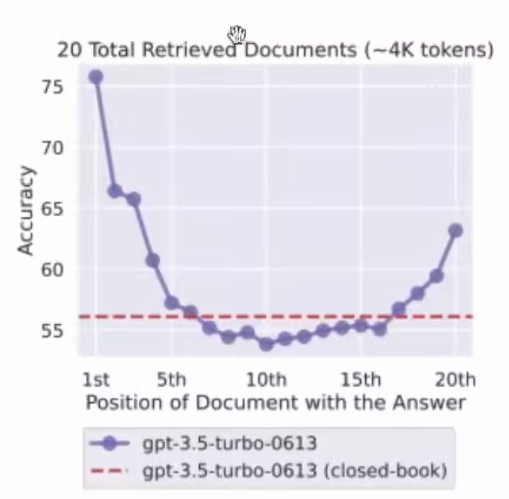

* 当问题回答语料位于长文中间位置时，需要注意
* 当需要从长文中获取答案时候

In [31]:
from langchain_core.vectorstores import InMemoryVectorStore

texts = [
    "西湖是杭州著名的旅游景点。",
    "我最喜欢的歌曲是《月亮代表我的心》。",
    "故宫是北京最著名的古迹之一。",
    "这是一篇关于北京故宫历史的文档。",
    "我非常喜欢去电影院看电影。",
    "北京故宫的藏品数量超过一百万件。",
    "这只是一段随机文本。",
    "《三国演义》是中国四大名著之一。",
    "紫禁城是故宫的别称，位于北京。",
    "故宫博物院每年接待游客数百万人次。",
]

# 创建检索器
retriever = InMemoryVectorStore.from_texts(texts, embedding=embeddings_model).as_retriever(
    search_kwargs={"k": 10} 
)

query = "请告诉我关于故宫的信息"

# 获取按相关性排序的文档
docs = retriever.invoke(query)

for doc in docs:
    print(f"- {doc.page_content}")

- 我最喜欢的歌曲是《月亮代表我的心》。
- 西湖是杭州著名的旅游景点。
- 《三国演义》是中国四大名著之一。
- 这只是一段随机文本。
- 紫禁城是故宫的别称，位于北京。
- 这是一篇关于北京故宫历史的文档。
- 北京故宫的藏品数量超过一百万件。
- 故宫是北京最著名的古迹之一。
- 我非常喜欢去电影院看电影。
- 故宫博物院每年接待游客数百万人次。


请注意，返回的文档按与查询的相关性降序排列。LongContextReorder文档转换器将实现上述重新排序:

In [34]:
from langchain_community.document_transformers import LongContextReorder

# 重新排序文档：
# 相关性较低的文档将位于列表中间
# 相关性较高的文档将位于开头和结尾
reordering = LongContextReorder()
reordering_docs = reordering.transform_documents(docs)

# 确认相关性高的文档位于开头和结尾
for doc in reordering_docs:
    print(f"- {doc.page_content}")

- 西湖是杭州著名的旅游景点。
- 这只是一段随机文本。
- 这是一篇关于北京故宫历史的文档。
- 故宫是北京最著名的古迹之一。
- 故宫博物院每年接待游客数百万人次。
- 我非常喜欢去电影院看电影。
- 北京故宫的藏品数量超过一百万件。
- 紫禁城是故宫的别称，位于北京。
- 《三国演义》是中国四大名著之一。
- 我最喜欢的歌曲是《月亮代表我的心》。


整合到Chain里面去

In [36]:
from langchain_classic.chains.combine_documents import create_stuff_documents_chain
from langchain_core.prompts import PromptTemplate
from langchain_openai import ChatOpenAI

model = ChatOpenAI(
    model="Qwen/Qwen3.8-27B",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

prompt_template = """
    Given these texts:
    -----
    {context}
    -----
    Please answer the following question:
    {query}
"""

prompt = PromptTemplate(
    template=prompt_template,
    input_variables=["context", "query"],
)

# Create and invoke the chain:
chain = create_stuff_documents_chain(model, prompt)
response = chain.invoke({"context": reordering_docs, "query": query})
print(response)



根据提供的文本，关于故宫的信息如下：

- 故宫是北京最著名的古迹之一。
- 故宫博物院每年接待游客数百万人次。
- 北京故宫的藏品数量超过一百万件。
- 紫禁城是故宫的别称，位于北京。


### 相似性分数
---

* 根据相似性打分过滤
* 为文档添加分数

### 相似性分数搜索
---
以 Chrome 为例

In [37]:
! pip install -qU langchain-chroma

In [47]:
from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma
import chromadb
import os

embeddings_model  = OpenAIEmbeddings(
    model="BAAI/bge-m3",       # 指定使用的 Embedding 模型名称
    openai_api_key=os.getenv("api_key"),   # 从环境变量读取 API 密钥
    openai_api_base=os.getenv("base_url")  # 从环境变量读取 API 请求地址（兼容 OpenAI 格式的自定义端点）
)

# 初始化chroma 客户端
vector_store = Chroma(
    collection_name="example_collection",
    embedding_function=embeddings_model,
    persist_directory="chroma_langchain_db",   # 可选参数，指定持久化目录
)


persistent_client = chromadb.PersistentClient()
collection = persistent_client.get_or_create_collection("collection_name")
collection.add(ids=["1", "2", "3"], documents=["a", "b", "c"])

vector_store_from_client = Chroma(
    client=persistent_client,             # 把硬盘客户端交出去
    collection_name="collection_name",    # 指定操作哪个集合（表）
    embedding_function=embeddings_model,  # 指定用哪个模型把文字变向量
)

# 添加一组文档
from uuid import uuid4
from langchain_core.documents import Document

document_1 = Document(
    page_content="I had chocolate chip pancakes and scrambled eggs for breakfast this morning.",
    metadata={"source": "tweet"},
    id=1,
)

document_2 = Document(
    page_content="The weather forecast for tomorrow is cloudyovercast,with a high of 62 degrees.",
    metadata={"source": "news"},
    id=2,
)

document_3 = Document(
    page_content="Building new project with LangChain - come check it out!",
    metadata={"source": "tweet"},
    id=3,
)

document_4 = Document(
    page_content="Robbers broke into the city bank and stole $1 million in cash.",
    metadata={"source": "news"},
    id=4,
)

document_5 = Document(
    page_content="Wow! That was an amazing movie. I can't wait to see it again.",
    metadata={"source": "tweet"},
    id=5,
)

document_6 = Document(
    page_content="Is the new iPhone worth the prive? Read this review to find out.",
    metadata={"source": "website"},
    id=6,
)

document_7 = Document(
    page_content="The top 10 soccer players in the world right now.",
    metadata={"source": "website"},
    id=7,
)

document_8 = Document(
    page_content="LangGraph is the best framework for building stateful, agentic applications!",
    metadata={"source": "tweet"},
    id=8,
)

document_9 = Document(
    page_content="The stock market is down 500 points today due to fears of a recession.",
    metadata={"source": "news"},
    id=9,
)

document_10 = Document(
    page_content="I have a bad feeling I am going to get deleted :(",
    metadata={"source": "tweet"},
    id=10,
)

documents = [
    document_1,
    document_2,
    document_3,
    document_4,
    document_5,
    document_6,
    document_7,
    document_8,
    document_9,
    document_10
]

uuids = [str(uuid4()) for _ in range(len(documents))]

vector_store.add_documents(documents=documents, ids=uuids)

['36b34473-9493-4cf4-b741-374d04719d66',
 'c043a4d0-6d7b-4a27-ae74-df21b6599ad5',
 '3f90e67f-27cf-439d-88ae-97251b62c381',
 '0221ef55-27b0-47e1-b0ef-8eb6661bfb41',
 'cfda37a2-5a24-421a-b8ca-25d59fd0dfb1',
 'c0071855-c08b-4f1f-acf8-ee791136f1cc',
 'ab938f4b-d839-4575-838d-ec1ead0f3b42',
 '948df3ed-5a35-41d2-b3ed-a6b4430f60ce',
 'e43b25a2-e6d7-4eed-9178-93913d0ead96',
 '6b4b99eb-28e7-44c7-a012-683ade793b67']

使用相似性分数检索

In [48]:
results = vector_store.similarity_search_with_relevance_scores(
    "Will it be hot tomorrow?", k=1, filter={"source": "news"}
)

for res, score in results:
    print(f"* [SIM={score:3f}] {res.page_content} [{res.metadata}]")

* [SIM=0.168519] The weather forecast for tomorrow is cloudyovercast,with a high of 62 degrees. [{'source': 'news'}]


### 为文档添加分数
---
通过一个自定义链，可以为原始文档增加相关性评分

In [50]:
from typing import List
from langchain_core.documents import Document
from langchain_core.runnables import chain

@chain
def retriever(query: str) -> List[Document]:
    docs, scores = zip(*vector_store.similarity_search_with_score(query))
    for doc, score in zip(docs, scores):
        doc.metadata["score"] = score

    return docs

result = retriever.invoke("Robbers")
result

(Document(id='36b34473-9493-4cf4-b741-374d04719d66', metadata={'source': 'tweet', 'score': 0.8026506900787354}, page_content='I had chocolate chip pancakes and scrambled eggs for breakfast this morning.'),
 Document(id='6b4b99eb-28e7-44c7-a012-683ade793b67', metadata={'source': 'tweet', 'score': 0.8308514952659607}, page_content='I have a bad feeling I am going to get deleted :('),
 Document(id='e43b25a2-e6d7-4eed-9178-93913d0ead96', metadata={'source': 'news', 'score': 0.8916018009185791}, page_content='The stock market is down 500 points today due to fears of a recession.'),
 Document(id='ab938f4b-d839-4575-838d-ec1ead0f3b42', metadata={'source': 'website', 'score': 0.9458252787590027}, page_content='The top 10 soccer players in the world right now.'))